# CSSD 模型（横截面收益标准差模型）

**用于检验羊群效应的行为金融模型**

$$
\text{CSSD} = \sqrt{\frac{\sum_{i=1}^{N} (r_i - r_m)^2}{N - 1}}
$$

其中：

$$
r_i \text{ 为个股 } i \text{ 的收益率}
$$$$
r_m \text{ 为市场组合的收益率}
$$$$
N \text{ 为样本中的股票数量}
$$

以 CSSD 作为被解释变量，以两个虚拟变量 $ D_t^u $ 和 $ D_t^d $ 作为解释变量，进行如下时序回归：

$$
\text{CSSD}_t = \alpha + \beta_1 D_t^u + \beta_2 D_t^d + \varepsilon_t
$$

其中：

$$
D_t^u = \begin{cases}1, & \text{若市场收益 } r_{m,t} \text{ 高于给定的上涨阈值} \\0, & \text{否则}\end{cases}
$$$$
D_t^d = \begin{cases}1, & \text{若市场收益 } r_{m,t} \text{ 低于给定的下跌阈值} \\0, & \text{否则}\end{cases}
$$

## 模型说明

CSSD 模型对羊群效应的检验，主要依据时序回归中市场极端收益项（即 $ D_t^u $ 和 $ D_t^d $）的回归系数 $ \beta_1 $ 和 $ \beta_2 $ 的符号及显著性。当 $ \beta_1 $ 或 $ \beta_2 $ 显著小于 0 时，表明在市场大幅上涨或大幅下跌的极端行情下，横截面收益标准差（CSSD）显著下降，意味着个股收益趋于一致，投资者的买卖行为趋向同步，从而反映出市场中存在明显的羊群效应。

数据：日度收盘价、日度可交易股票数量

In [1]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def calculate_cssd_beta_factor(
    start_date,
    end_date,
    factor_type=0,
    regression_window=252,
    upper_threshold=0.03,
    lower_threshold=-0.03,
    market_ids=None,
    batch_size=500,
    min_market_stocks=500,
    min_extreme_days=5,
):
    """
    计算日频滚动 CSSD 羊群效应因子。

    参数
    ----
    factor_type : int
        0：输出 beta1，即极端上涨日虚拟变量 D_up 的滚动回归系数；
        1：输出 beta2，即极端下跌日虚拟变量 D_down 的滚动回归系数。

    regression_window : int
        每日回归使用的历史交易日窗口，例如 252。

    upper_threshold, lower_threshold : float
        市场极端上涨／下跌阈值。例如 0.03 表示单日上涨超过 3%。

    返回
    ----
    DataFrame
        单层日期索引，列名为 CSSD_beta1 或 CSSD_beta2。
        每个 T 日的值仅使用截至 T 日的数据估计，可用于 T+1 日交易。
    """
    if factor_type not in (0, 1):
        raise ValueError("factor_type 只能为 0（beta1）或 1（beta2）。")

    if lower_threshold >= upper_threshold:
        raise ValueError("lower_threshold 必须小于 upper_threshold。")

    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        # 252 个 CSSD 观测值需要额外取 252 个交易日价格
        lookback_days=regression_window,
    )

    market_ids = _get_ids(market_ids)
    return_dates = price_dates[1:]

    # 汇总每日的收益和、收益平方和、有效股票数。
    return_sum = pd.Series(0.0, index=return_dates)
    return_sq_sum = pd.Series(0.0, index=return_dates)
    stock_count = pd.Series(0, index=return_dates, dtype="int64")

    for start in range(0, len(market_ids), batch_size):
        batch = market_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        return_sum += returns.sum(axis=1, skipna=True)
        return_sq_sum += returns.pow(2).sum(axis=1, skipna=True)
        stock_count += returns.notna().sum(axis=1).astype("int64")

    # r_m,t：全市场当日有效股票收益率等权平均。
    market_return = return_sum / stock_count.replace(0, np.nan)

    # CSSD_t^2 = [sum(r_i^2) - N * r_m^2] / (N - 1)
    squared_deviation_sum = (
        return_sq_sum - stock_count * market_return.pow(2)
    ).clip(lower=0)

    cssd = np.sqrt(
        squared_deviation_sum / (stock_count - 1).replace(0, np.nan)
    )

    state = pd.DataFrame({
        "market_return": market_return,
        "CSSD": cssd,
        "N": stock_count,
    })

    # 有效股票太少的交易日不参与回归。
    state.loc[
        state["N"] < min_market_stocks,
        ["market_return", "CSSD"],
    ] = np.nan

    state = state.dropna(subset=["market_return", "CSSD"]).copy()

    # D_up 对应 beta1；D_down 对应 beta2。
    state["D_up"] = (
        state["market_return"] > upper_threshold
    ).astype(float)

    state["D_down"] = (
        state["market_return"] < lower_threshold
    ).astype(float)

    beta_result = pd.DataFrame(
        np.nan,
        index=state.index,
        columns=["CSSD_beta1", "CSSD_beta2"],
    )

    # 每个交易日 T 都仅使用截至 T 的 regression_window 个交易日回归。
    for end_pos in range(regression_window - 1, len(state)):
        sample = state.iloc[
            end_pos - regression_window + 1:end_pos + 1
        ]

        # 若窗口中上涨或下跌极端日过少，系数不具可解释性。
        if (
            sample["D_up"].sum() < min_extreme_days
            or sample["D_down"].sum() < min_extreme_days
        ):
            continue

        y = sample["CSSD"].values
        X = np.column_stack([
            np.ones(len(sample)),
            sample["D_up"].values,
            sample["D_down"].values,
        ])

        # alpha、beta1、beta2
        coefficients = np.linalg.lstsq(X, y, rcond=None)[0]

        beta_result.iloc[end_pos, 0] = coefficients[1]
        beta_result.iloc[end_pos, 1] = coefficients[2]

    # 最终只输出用户要求区间内的日频因子。
    beta_result = beta_result.reindex(target_dates)

    if factor_type == 0:
        return beta_result[["CSSD_beta1"]]
    else:
        return beta_result[["CSSD_beta2"]]

In [2]:
cssd_beta1 = calculate_cssd_beta_factor(
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_type=0,
    regression_window=252,
    upper_threshold=0.02,
    lower_threshold=-0.02,
)

cssd_beta1.head()

,CSSD_beta1
2020-01-02,-0.000289
2020-01-03,-0.000312
2020-01-06,-0.000339
2020-01-07,-0.000352
2020-01-08,-0.000364


,指标,数值,判断
0,总交易日数,1455,
1,有效 beta 观测数,1360,
2,缺失值数,95,初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3,最长连续缺失天数,59,若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4,重复日期,0,应为 0
5,日期是否升序,True,应为 True
6,无穷值,0,应为 0
7,首个有效 beta 日期,2020-01-02,通常在滚动窗口形成后才出现
8,负 beta 占比,0.114706,负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9,均值,0.002885,单位为收益率；0.01 表示 1 个百分点


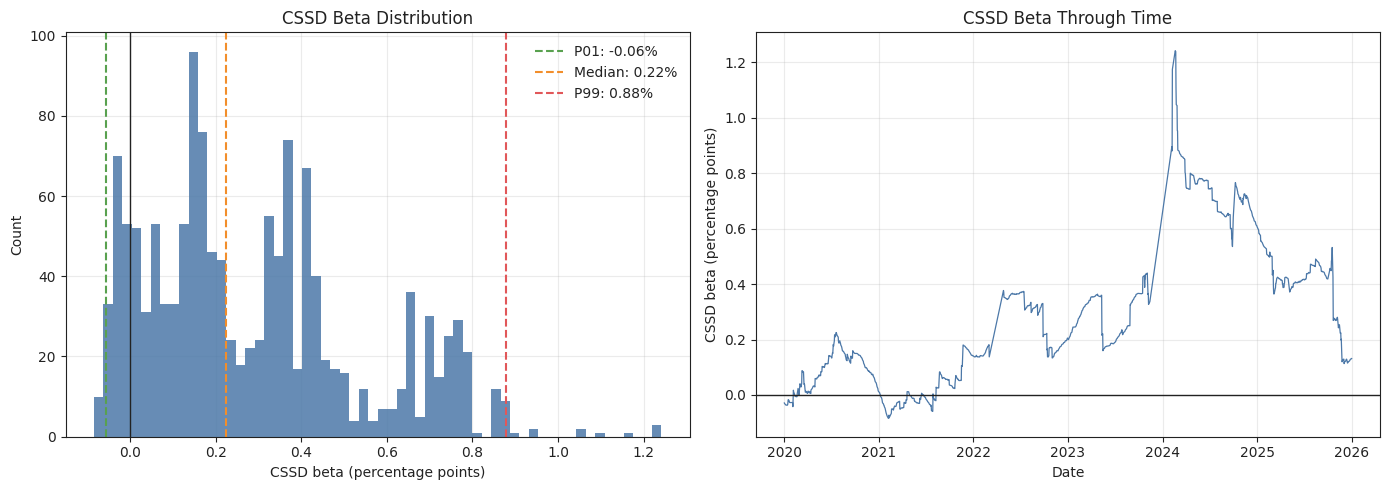

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 若检验 beta2，只需改为 cssd_beta2 和 "CSSD_beta2"
factor = cssd_beta1.copy()
factor_name = "CSSD_beta1"
review_threshold = 0.05  # |beta| 超过 5 个百分点时人工核查

# 兼容 Series 或单列 DataFrame
if isinstance(factor, pd.Series):
    factor = factor.to_frame(name=factor_name)

if factor_name not in factor.columns:
    factor_name = factor.columns[0]

beta = pd.to_numeric(factor[factor_name], errors="coerce")
beta.index = pd.to_datetime(beta.index)

duplicate_count = int(beta.index.duplicated().sum())
is_sorted = beta.index.is_monotonic_increasing
missing_count = int(beta.isna().sum())
inf_count = int(np.isinf(beta.dropna().values).sum())

valid = beta.replace([np.inf, -np.inf], np.nan).dropna()
if valid.empty:
    raise ValueError("没有有效的 CSSD beta 值，请检查回归窗口和极端日阈值。")

invalid = beta.replace([np.inf, -np.inf], np.nan).isna()
longest_missing_run = int(
    invalid.groupby((~invalid).cumsum()).sum().max()
)

summary = pd.DataFrame({
    "指标": [
        "总交易日数",
        "有效 beta 观测数",
        "缺失值数",
        "最长连续缺失天数",
        "重复日期",
        "日期是否升序",
        "无穷值",
        "首个有效 beta 日期",
        "负 beta 占比",
        "均值",
        "标准差",
        "最小值",
        "1%分位数",
        "中位数",
        "99%分位数",
        "最大值",
        "|beta| > 5% 的观测数",
        "日变化绝对值 99%分位数",
    ],
    "数值": [
        len(beta),
        len(valid),
        missing_count,
        longest_missing_run,
        duplicate_count,
        is_sorted,
        inf_count,
        valid.index.min().strftime("%Y-%m-%d"),
        (valid < 0).mean(),
        valid.mean(),
        valid.std(),
        valid.min(),
        valid.quantile(0.01),
        valid.median(),
        valid.quantile(0.99),
        valid.max(),
        int((valid.abs() > review_threshold).sum()),
        valid.diff().abs().quantile(0.99),
    ],
    "判断": [
        "",
        "",
        "初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误",
        "若中间出现很长缺失，检查 min_extreme_days 与市场阈值",
        "应为 0",
        "应为 True",
        "应为 0",
        "通常在滚动窗口形成后才出现",
        "负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号",
        "单位为收益率；0.01 表示 1 个百分点",
        "检查 beta 的时间稳定性",
        "无需强制为正或负",
        "",
        "",
        "",
        "",
        "超过阈值仅人工复核，不自动判错",
        "过大跳变需检查滚动窗口中的极端日变化",
    ],
})

display(summary)

# ---------- 绘图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

beta_pct = valid * 100
p01, p50, p99 = valid.quantile([0.01, 0.50, 0.99]).values * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左：分布
axes[0].hist(beta_pct, bins=60, color="#4C78A8", alpha=0.85)
axes[0].axvline(0, color="#222222", linewidth=1)
axes[0].axvline(p01, color="#59A14F", linestyle="--", label="P01: {:.2f}%".format(p01))
axes[0].axvline(p50, color="#F28E2B", linestyle="--", label="Median: {:.2f}%".format(p50))
axes[0].axvline(p99, color="#E15759", linestyle="--", label="P99: {:.2f}%".format(p99))
axes[0].set_title("CSSD Beta Distribution")
axes[0].set_xlabel("CSSD beta (percentage points)")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 右：时间序列
axes[1].plot(valid.index, beta_pct, color="#4C78A8", linewidth=0.9)
axes[1].axhline(0, color="#222222", linewidth=1)
axes[1].set_title("CSSD Beta Through Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("CSSD beta (percentage points)")
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

'''
upper_threshold=0.03
lower_threshold=-0.03

指标	数值	判断
0	总交易日数	1455	
1	有效 beta 观测数	687	
2	缺失值数	768	初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3	最长连续缺失天数	708	若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4	重复日期	0	应为 0
5	日期是否升序	True	应为 True
6	无穷值	0	应为 0
7	首个有效 beta 日期	2020-01-02	通常在滚动窗口形成后才出现
8	负 beta 占比	0.250364	负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9	均值	0.00453444	单位为收益率；0.01 表示 1 个百分点
10	标准差	0.00436959	检查 beta 的时间稳定性
11	最小值	-0.00162186	无需强制为正或负
12	1%分位数	-0.00149711	
13	中位数	0.00566154	
14	99%分位数	0.0112108	
15	最大值	0.011226	
16	|beta| > 5% 的观测数	0	超过阈值仅人工复核，不自动判错
17	日变化绝对值 99%分位数	0.00143277	过大跳变需检查滚动窗口中的极端日变化
'''

plt.tight_layout()
plt.show()

In [3]:
cssd_beta2 = calculate_cssd_beta_factor(
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_type=1,
    regression_window=252,
    upper_threshold=0.02,
    lower_threshold=-0.02,
)

cssd_beta2.head()

,CSSD_beta2
2020-01-02,0.005403
2020-01-03,0.005380
2020-01-06,0.005353
2020-01-07,0.005340
2020-01-08,0.005328


,指标,数值,判断
0,总交易日数,1455,
1,有效 beta 观测数,1360,
2,缺失值数,95,初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3,最长连续缺失天数,59,若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4,重复日期,0,应为 0
5,日期是否升序,True,应为 True
6,无穷值,0,应为 0
7,首个有效 beta 日期,2020-01-02,通常在滚动窗口形成后才出现
8,负 beta 占比,0.0,负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9,均值,0.005219,单位为收益率；0.01 表示 1 个百分点


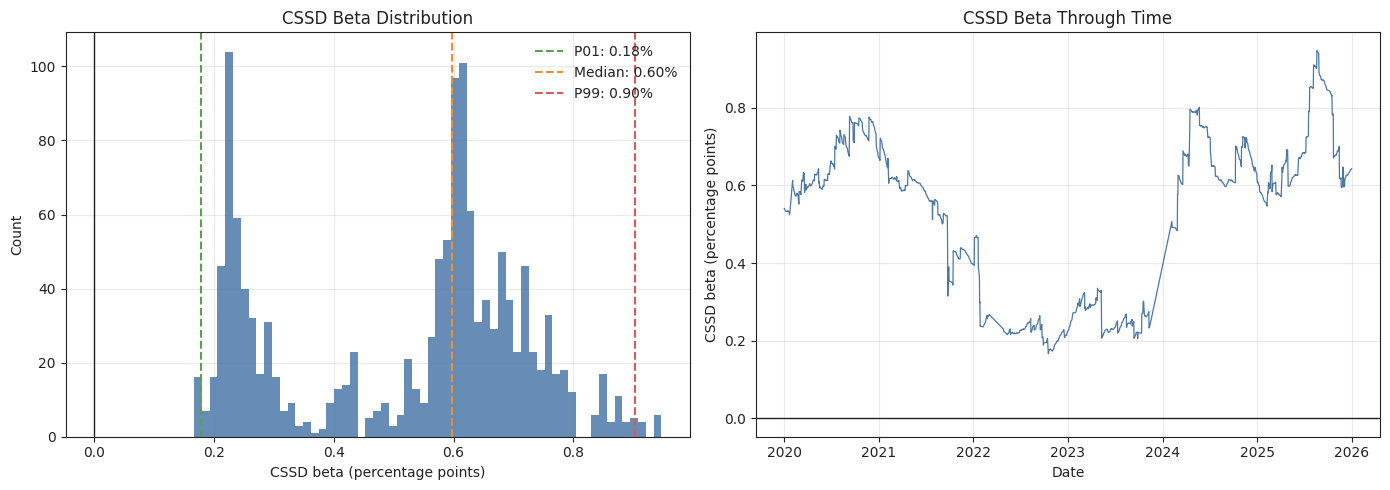

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 若检验 beta2，只需改为 cssd_beta2 和 "CSSD_beta2"
factor = cssd_beta2.copy()
factor_name = "CSSD_beta2"
review_threshold = 0.05  # |beta| 超过 5 个百分点时人工核查

# 兼容 Series 或单列 DataFrame
if isinstance(factor, pd.Series):
    factor = factor.to_frame(name=factor_name)

if factor_name not in factor.columns:
    factor_name = factor.columns[0]

beta = pd.to_numeric(factor[factor_name], errors="coerce")
beta.index = pd.to_datetime(beta.index)

duplicate_count = int(beta.index.duplicated().sum())
is_sorted = beta.index.is_monotonic_increasing
missing_count = int(beta.isna().sum())
inf_count = int(np.isinf(beta.dropna().values).sum())

valid = beta.replace([np.inf, -np.inf], np.nan).dropna()
if valid.empty:
    raise ValueError("没有有效的 CSSD beta 值，请检查回归窗口和极端日阈值。")

invalid = beta.replace([np.inf, -np.inf], np.nan).isna()
longest_missing_run = int(
    invalid.groupby((~invalid).cumsum()).sum().max()
)

summary = pd.DataFrame({
    "指标": [
        "总交易日数",
        "有效 beta 观测数",
        "缺失值数",
        "最长连续缺失天数",
        "重复日期",
        "日期是否升序",
        "无穷值",
        "首个有效 beta 日期",
        "负 beta 占比",
        "均值",
        "标准差",
        "最小值",
        "1%分位数",
        "中位数",
        "99%分位数",
        "最大值",
        "|beta| > 5% 的观测数",
        "日变化绝对值 99%分位数",
    ],
    "数值": [
        len(beta),
        len(valid),
        missing_count,
        longest_missing_run,
        duplicate_count,
        is_sorted,
        inf_count,
        valid.index.min().strftime("%Y-%m-%d"),
        (valid < 0).mean(),
        valid.mean(),
        valid.std(),
        valid.min(),
        valid.quantile(0.01),
        valid.median(),
        valid.quantile(0.99),
        valid.max(),
        int((valid.abs() > review_threshold).sum()),
        valid.diff().abs().quantile(0.99),
    ],
    "判断": [
        "",
        "",
        "初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误",
        "若中间出现很长缺失，检查 min_extreme_days 与市场阈值",
        "应为 0",
        "应为 True",
        "应为 0",
        "通常在滚动窗口形成后才出现",
        "负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号",
        "单位为收益率；0.01 表示 1 个百分点",
        "检查 beta 的时间稳定性",
        "无需强制为正或负",
        "",
        "",
        "",
        "",
        "超过阈值仅人工复核，不自动判错",
        "过大跳变需检查滚动窗口中的极端日变化",
    ],
})

display(summary)

# ---------- 绘图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

beta_pct = valid * 100
p01, p50, p99 = valid.quantile([0.01, 0.50, 0.99]).values * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左：分布
axes[0].hist(beta_pct, bins=60, color="#4C78A8", alpha=0.85)
axes[0].axvline(0, color="#222222", linewidth=1)
axes[0].axvline(p01, color="#59A14F", linestyle="--", label="P01: {:.2f}%".format(p01))
axes[0].axvline(p50, color="#F28E2B", linestyle="--", label="Median: {:.2f}%".format(p50))
axes[0].axvline(p99, color="#E15759", linestyle="--", label="P99: {:.2f}%".format(p99))
axes[0].set_title("CSSD Beta Distribution")
axes[0].set_xlabel("CSSD beta (percentage points)")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 右：时间序列
axes[1].plot(valid.index, beta_pct, color="#4C78A8", linewidth=0.9)
axes[1].axhline(0, color="#222222", linewidth=1)
axes[1].set_title("CSSD Beta Through Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("CSSD beta (percentage points)")
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

'''
upper_threshold=0.03
lower_threshold=-0.03

指标	数值	判断
0	总交易日数	1455	
1	有效 beta 观测数	687	
2	缺失值数	768	初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3	最长连续缺失天数	708	若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4	重复日期	0	应为 0
5	日期是否升序	True	应为 True
6	无穷值	0	应为 0
7	首个有效 beta 日期	2020-01-02	通常在滚动窗口形成后才出现
8	负 beta 占比	0	负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9	均值	0.00988442	单位为收益率；0.01 表示 1 个百分点
10	标准差	0.00102633	检查 beta 的时间稳定性
11	最小值	0.0080556	无需强制为正或负
12	1%分位数	0.00812307	
13	中位数	0.00982598	
14	99%分位数	0.0123125	
15	最大值	0.0123272	
16	|beta| > 5% 的观测数	0	超过阈值仅人工复核，不自动判错
17	日变化绝对值 99%分位数	0.00114114	过大跳变需检查滚动窗口中的极端日变化
'''

'''
旧结果分析

数据本身没有完整性或数值异常，但当前参数下滚动回归的可用性不足。
项目	beta1（上涨极端）	beta2（下跌极端）	结论
有效观测	687 / 1455	687 / 1455	仅 47.2% 可用
最长连续缺失	708 日	708 日	明显过长
均值	+0.453 个百分点	+0.988 个百分点	CSSD 在极端日平均上升
负值占比	25.0%	0%	下跌情形没有羊群效应方向


关键结论：
- 结构质量通过：无重复、无无穷值、日期有序，beta 的数值范围也合理，没有异常爆点。
- beta1 只有 25% 为负，且最小仅为 -0.162 个百分点；均值与中位数都为正。
- beta2 全部为正，意味着极端下跌日的 CSSD 比普通日更高，个股分歧扩大，而非收益趋同。
- 因此，就当前样本和参数而言，没有看到稳定的 CSSD 羊群效应证据。正式结论仍需回归 t 值或置信区间支持。
- 708 日连续缺失不是数据坏了，而是滚动 252 日窗口中，市场收益 > 3% 或 < -3% 的天数不足 5 天。你的代码要求上下两类极端日都至少出现 5 次，因此 beta1、beta2 会在同一时期同时缺失。
首个有效值是 2020-01-02 是正常的：计算函数已额外取了 2019 年的 252 日历史价格。
如果希望得到连续、可用的日频滚动 beta，建议先将阈值改为：
upper_threshold=0.02
lower_threshold=-0.02
min_extreme_days=5
再重新运行同样的检查。2% 阈值会增加极端日样本，通常能显著减少长时间缺失；然后比较新旧阈值下 beta 的符号和稳定性。
'''

'''
新结果分析：

这组参数明显更合适：有效覆盖率从 47.2% 提升到 93.5%，最长连续缺失从 708 日降到 59 日。数据完整性、分布和稳定性都可以通过。
- beta1：均值 +0.288 个百分点，仅 11.5% 为负；
- beta2：均值 +0.522 个百分点，全样本始终为正；
- 两者均没有异常极值，日变化也比原参数更平稳。
经济解释上，结论仍然很清楚：在当前全 A 等权市场收益、2% 阈值和 252 日窗口下，极端上涨或下跌日的 CSSD 通常上升，而不是下降。尤其 beta2 始终为正，表示市场下跌较大时股票收益分歧扩大，并未出现 CSSD 模型定义的下跌羊群效应。
因此：
- 因子输出质量：通过；
- 参数可用性：2% 阈值优于 3% 阈值；
- 羊群效应结论：当前仅从系数方向看，不支持显著羊群效应。
正式研究报告中还需要补充滚动回归系数的 t 值或置信区间；只有 beta 显著小于 0，才能严格确认羊群效应。
'''

plt.tight_layout()
plt.show()

你的结果讲的是一个很清晰的金融故事：在 2020–2025 的全 A 等权市场中，市场出现较大波动时，股票之间的收益分歧通常扩大，而不是收敛。因此，按 CSSD 的定义，数据并不支持明显的羊群效应。

## 先把 CSSD 翻译成直觉

CSSD 不是一只股票的波动率，而是“**同一天，不同股票的收益离市场平均收益有多远**”。

- 如果市场上涨 2%，大多数股票也都在约 2% 附近上涨，例如 1.8%、2.0%、2.2%，则 CSSD 很低：大家走势一致。
- 如果市场上涨 2%，但有的股票涨 8%，有的涨 2%，有的跌 3%，则 CSSD 很高：大家对行情的反应不同。

羊群效应的核心假设是：市场剧烈波动时，投资者放弃一部分自身信息、跟随市场共识买卖，因此股票收益会向市场收益靠拢，CSSD 应下降。Christie 和 Huang 的原始 CSSD 思路正是用“极端市场日的横截面离散度是否降低”来识别这种现象；相反，传统理性定价下，不同股票对市场冲击的敏感度不同，离散度往往会上升。[原始 CSSD 研究](https://www.tandfonline.com/doi/abs/10.2469/faj.v51.n4.1918)

## 你的回归系数究竟表示什么

由于 `D_up`、`D_down` 和普通日互斥，你的回归可以直接理解为：

| 市场状态 | 预期 CSSD |
|---|---|
| 普通日 | `α` |
| 市场收益 > 2% | `α + β1` |
| 市场收益 < -2% | `α + β2` |

所以：

- `β1 < 0`：极端上涨日的 CSSD 比普通日低，支持上涨羊群；
- `β2 < 0`：极端下跌日的 CSSD 比普通日低，支持下跌羊群；
- `β > 0`：极端行情下 CSSD 更高，股票反应更分化，不支持 CSSD 羊群。

你的 beta 单位和收益率相同。`0.002885` 不是 0.2885%，而是 **CSSD 增加 0.2885 个百分点，即 28.85 个基点**。

## 结合你的 2% 阈值结果

### 上涨极端日：beta1

`beta1` 均值为 `+0.002885`，中位数为 `+0.002242`。

这意味着，在过去 252 个交易日的滚动样本中，市场单日上涨超过 2% 时，CSSD 平均比普通日高约 **0.29 个百分点**。也就是说，行情大涨时并非所有股票同步上行，反而出现了更明显的强弱分化。

虽然 11.5% 的滚动窗口中 beta1 为负，但负值很小：

- 最低值仅 `-0.000843`，即 -8.43 个基点；
- 99% 分位数为 `+0.008793`，即 +87.93 个基点；
- 均值和中位数都为正。

所以，beta1 的总体信息不是“上涨时存在稳定羊群”，而是“上涨时通常分化，少数时期可能出现轻微收敛”。

### 下跌极端日：beta2

`beta2` 全部为正，范围为：

- 最小值：`+0.001670`，即 +16.70 个基点；
- 中位数：`+0.005977`，即 +59.77 个基点；
- 均值：`+0.005219`，即 +52.19 个基点。

这比 beta1 更明确：市场下跌超过 2% 时，CSSD 从未低于普通日，而是稳定上升。直觉上，虽然市场整体下跌，但不同股票并没有“一起跌、按相近幅度跌”；有的跌得更重，有的相对抗跌，横截面分歧被放大。

因此，就 CSSD 的判别标准而言，**下跌时不存在羊群效应证据**；结果反而更接近“压力行情下的收益分化”。

## 为什么“市场大跌”不一定会产生羊群

市场下跌时，投资者可能确实更紧张，但“紧张”与“收益趋同”不是同一件事。

CSSD 上升可能来自：

- 不同行业受到冲击程度不同；
- 高估值、高杠杆、小市值股票被更集中抛售；
- 防御性行业或低波动股票相对抗跌；
- 个股基本面、政策预期、流动性和涨跌停约束不同；
- 股票对市场的 beta 不同，市场波动本身就会放大横截面差异。

所以，`β2 > 0` 不等于“投资者绝对理性”，而是说明他们的最终交易结果没有表现为“围绕市场平均收益收敛”。CSSD 是行为结果的检验，不能单独证明心理机制。

## 为什么 2% 阈值比 3% 更可用

3% 阈值时，有效 beta 只有 687 个、最长连续缺失 708 日。原因是 252 日窗口内，上涨和下跌极端日都必须至少出现 5 次；固定 ±3% 对全 A 等权市场过于严格，许多窗口无法估计完整回归。

改为 ±2% 后：

- 有效 beta 达到 1,360 个；
- 覆盖率约 93.5%；
- 最长连续缺失降为 59 日；
- beta 的日变化更平稳；
- 不存在数值爆点。

但要注意：2% 与 3% 检验的是不同强度的市场压力。2% 并不是“修复”3% 的结果，而是将研究问题从“极端压力下是否羊群”改为“较大市场波动下是否羊群”。论文或报告中应预先说明阈值，并把 2%、2.5%、3% 做成稳健性比较，而不是只保留最容易得到连续输出的一组。

## 目前能下的结论

你的因子输出质量已经通过；2% 阈值下的滚动 CSSD beta 也足够连续、数值合理。

但金融结论应写成：

> 在全 A 等权市场、20 日收益数据清洗规则、252 日滚动窗口和 ±2% 市场收益阈值下，极端上涨与下跌日的 CSSD 整体高于普通日，尤其极端下跌日的 CSSD 在全部有效滚动窗口中均高于普通日。因此，样本不支持基于 CSSD 的收益趋同式羊群效应；市场压力更可能伴随横截面收益分化。

最后，当前只有系数，没有标准误和 t 值。严格认定羊群效应需要检验 `β1` 或 `β2` 是否显著小于零；而且滚动窗口高度重叠，不能把 1,360 个 beta 当作 1,360 个独立证据。建议下一步输出每个窗口的 `alpha、beta1、beta2、t 值、D_up 天数、D_down 天数`，再做显著性和阈值稳健性检验。作为稳健性补充，也可采用 CSAD 的非线性回归检验；这是文献中常用的另一种离散度方法。[Chang、Cheng 与 Khorana 的 CSAD 扩展研究](https://www.sciencedirect.com/science/article/pii/S0378426699000965)

In [7]:
cssd_signal = cssd_beta1.join(cssd_beta2).sort_index()
display(cssd_signal.tail())

,CSSD_beta1,CSSD_beta2
2025-12-25,0.001266,0.006374
2025-12-26,0.001286,0.006394
2025-12-29,0.001302,0.006410
2025-12-30,0.001302,0.006416
2025-12-31,0.001313,0.006426


In [9]:
cssd_signal.to_csv("cssd_signal.csv", index_label="date")

做一个最基础的“羊群效应风险开关”回测。这里的示例逻辑是：CSSD_beta1 处于过去一年最低 20% 时，代表上涨极端行情下的羊群效应较强，次日降低市场 ETF 风险敞口；否则持有 ETF。

这个回测回答的是：CSSD 羊群效应是否能帮助规避未来市场风险、改善 ETF 持有策略的夏普和最大回撤。
注意，beta1 < 0 或 beta2 < 0 仅说明羊群效应的统计证据；它本身并不自动意味着“明天市场必跌”。所以应至少比较三种规则：
- 仅用 CSSD_beta1 做上涨羊群风险开关；
- 仅用 CSSD_beta2 做下跌羊群风险开关；
- 两者任一处于自身历史低分位时共同降低仓位。
如果你的目标仍是做股票 IC 和五分组收益，则需要改造成“行业 / 板块级 CSSD”或“每只股票所属群体的 CSSD beta”，再将群体值映射回各股票；当前全市场 CSSD 不能直接充当横截面选股因子。

## 拓展：行业内的CSSD模型

In [4]:
import matplotlib as mpl
from matplotlib import font_manager as fm


def setup_chinese_font(font_path=None):
    """
    自动寻找 Notebook 环境已安装的中文字体。
    若没有，可传入自行上传的 .ttf / .otf / .ttc 文件绝对路径。
    """
    if font_path is not None:
        fm.fontManager.addfont(font_path)
        font_name = fm.FontProperties(fname=font_path).get_name()

    else:
        candidate_fonts = [
            "Noto Sans CJK SC",
            "Noto Serif CJK SC",
            "Source Han Sans SC",
            "Source Han Serif SC",
            "WenQuanYi Zen Hei",
            "WenQuanYi Micro Hei",
            "AR PL UMing CN",
            "AR PL UKai CN",
            "Microsoft YaHei",
            "SimHei",
            "PingFang SC",
        ]

        installed_fonts = {
            font.name for font in fm.fontManager.ttflist
        }

        font_name = next(
            (
                name for name in candidate_fonts
                if name in installed_fonts
            ),
            None,
        )

    if font_name is None:
        print(
            "未找到中文字体。请上传 NotoSansCJKsc-Regular.otf "
            "或其他中文字体文件，并传入其 font_path。"
        )
        return False

    mpl.rcParams["font.family"] = font_name
    mpl.rcParams["font.sans-serif"] = [font_name]
    mpl.rcParams["axes.unicode_minus"] = False

    print("当前绘图中文字体：{}".format(font_name))
    return True


HAS_CHINESE_FONT = setup_chinese_font()

当前绘图中文字体：WenQuanYi Micro Hei


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rqdatac import (
    all_instruments,
    get_price,
    get_trading_dates,
    get_instrument_industry,
)


# ============================================================
# 1. 数据与行业分类工具
# ============================================================

def _icssd_chunks(items, size):
    for start in range(0, len(items), size):
        yield items[start:start + size]


def _icssd_get_a_share_ids(candidate_ids=None):
    """默认使用沪深 A 股，排除 B 股。"""
    if candidate_ids is not None:
        return list(dict.fromkeys(candidate_ids))

    instruments = all_instruments("CS").copy()
    order_book_id = instruments["order_book_id"].astype(str)

    mask = (
        instruments["exchange"].isin(["XSHG", "XSHE"])
        & ~order_book_id.str.startswith(("900", "200"))
    )

    return (
        instruments.loc[mask, "order_book_id"]
        .dropna()
        .drop_duplicates()
        .tolist()
    )


def _icssd_prepare_dates(start_date, end_date, regression_window):
    """
    输出区间为 [start_date, end_date]；
    额外向前取 regression_window 个交易日，保证起始日已有完整回归窗口。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max(regression_window * 4, 1000)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("指定区间内没有交易日。")

    first_position = calendar.get_loc(target_dates[0])
    last_position = calendar.get_loc(target_dates[-1])

    if first_position < regression_window:
        raise ValueError("起始日前的历史交易日不足。")

    # regression_window 个收益率需要 regression_window + 1 个价格日
    price_dates = calendar[
        first_position - regression_window:last_position + 1
    ]

    return target_dates, price_dates


def _icssd_download_returns(order_book_ids, price_dates, batch_size=500):
    """
    下载复权收盘价和成交量，构造日收益率。

    仅保留前后两个交易日都正常交易的收益率，避免停牌复牌日造成异常跳涨。
    """
    return_dates = price_dates[1:]
    blocks = []

    for batch in _icssd_chunks(order_book_ids, batch_size):
        raw = get_price(
            order_book_ids=batch,
            start_date=price_dates[0],
            end_date=price_dates[-1],
            frequency="1d",
            fields=["close", "volume"],
            adjust_type="pre",
            skip_suspended=False,
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            close = raw["close"].unstack("order_book_id")
            volume = raw["volume"].unstack("order_book_id")
        else:
            # 单标的时的兼容处理
            close = raw[["close"]].copy()
            volume = raw[["volume"]].copy()
            close.columns = [batch[0]]
            volume.columns = [batch[0]]

        close.index = pd.to_datetime(close.index)
        volume.index = pd.to_datetime(volume.index)

        close = close.reindex(index=price_dates, columns=batch)
        volume = volume.reindex(index=price_dates, columns=batch)

        returns = close.pct_change(fill_method=None).iloc[1:]

        traded_today = volume.iloc[1:].gt(0)
        traded_yesterday = volume.shift(1).iloc[1:].gt(0)

        valid_price = (
            close.iloc[1:].gt(0)
            & close.shift(1).iloc[1:].gt(0)
        )

        returns = returns.where(
            traded_today & traded_yesterday & valid_price
        )

        blocks.append(returns)

    if not blocks:
        raise RuntimeError("未下载到有效价格数据。")

    return (
        pd.concat(blocks, axis=1)
        .reindex(index=return_dates, columns=order_book_ids)
        .astype(float)
    )


def _icssd_get_industry_snapshot(
    order_book_ids,
    date,
    industry_source="citics_2019",
    industry_level=1,
    batch_size=1000,
):
    """获取某日中信一级行业代码和行业名称。"""
    if industry_level != 1:
        raise ValueError("当前版本仅支持 industry_level=1。")

    blocks = []

    for batch in _icssd_chunks(order_book_ids, batch_size):
        raw = get_instrument_industry(
            order_book_ids=batch,
            source=industry_source,
            level=industry_level,
            date=date,
        )

        if raw is None or len(raw) == 0:
            continue

        data = raw.copy()

        if isinstance(data.index, pd.MultiIndex) or data.index.name is not None:
            data = data.reset_index()

        if "order_book_id" not in data.columns:
            possible_columns = [
                col for col in data.columns
                if str(col).lower() in (
                    "order_book_id", "instrument", "symbol"
                )
            ]

            if not possible_columns:
                raise ValueError(
                    "行业数据中无法识别 order_book_id，当前列为：{}".format(
                        list(data.columns)
                    )
                )

            data = data.rename(
                columns={possible_columns[0]: "order_book_id"}
            )

        if "first_industry_code" not in data.columns:
            raise ValueError(
                "行业数据缺少 first_industry_code，当前列为：{}".format(
                    list(data.columns)
                )
            )

        keep_columns = ["order_book_id", "first_industry_code"]

        if "first_industry_name" in data.columns:
            keep_columns.append("first_industry_name")

        block = data[keep_columns].copy()
        block = block.rename(
            columns={
                "first_industry_code": "industry_code",
                "first_industry_name": "industry_name",
            }
        )

        if "industry_name" not in block.columns:
            block["industry_name"] = block["industry_code"].astype(str)

        blocks.append(block)

    if not blocks:
        return pd.DataFrame(
            columns=["industry_code", "industry_name"]
        )

    result = pd.concat(blocks, axis=0, ignore_index=True)
    result = result.drop_duplicates(
        subset=["order_book_id"], keep="last"
    )

    return result.set_index("order_book_id")


def _icssd_build_industry_labels(
    order_book_ids,
    dates,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    industry_batch_size=1000,
):
    """
    生成 日期 × 股票 的行业标签矩阵。

    行业归属按月初更新，避免使用未来行业归属。
    """
    dates = pd.DatetimeIndex(dates)
    n_dates = len(dates)
    n_stocks = len(order_book_ids)

    labels = np.full(
        (n_dates, n_stocks),
        fill_value=-1,
        dtype=np.int32,
    )

    id_to_position = {
        stock_id: position
        for position, stock_id in enumerate(order_book_ids)
    }

    refresh = industry_refresh.upper()

    if refresh == "M":
        periods = dates.to_period("M")
    elif refresh == "Q":
        periods = dates.to_period("Q")
    else:
        raise ValueError("industry_refresh 只能为 'M' 或 'Q'。")

    update_positions = np.flatnonzero(
        np.r_[True, periods[1:] != periods[:-1]]
    )

    code_to_label = {}
    label_to_code = []
    industry_names = {}

    for seq, start_position in enumerate(update_positions):
        end_position = (
            update_positions[seq + 1]
            if seq + 1 < len(update_positions)
            else n_dates
        )

        snapshot = _icssd_get_industry_snapshot(
            order_book_ids=order_book_ids,
            date=dates[start_position],
            industry_source=industry_source,
            industry_level=industry_level,
            batch_size=industry_batch_size,
        )

        one_day_labels = np.full(
            n_stocks,
            fill_value=-1,
            dtype=np.int32,
        )

        for stock_id, row in snapshot.iterrows():
            if stock_id not in id_to_position:
                continue

            industry_code = row["industry_code"]

            if pd.isna(industry_code):
                continue

            industry_code = str(industry_code)

            if industry_code not in code_to_label:
                code_to_label[industry_code] = len(code_to_label)
                label_to_code.append(industry_code)

            label = code_to_label[industry_code]

            one_day_labels[id_to_position[stock_id]] = label

            industry_name = row.get("industry_name", industry_code)

            if pd.notna(industry_name):
                industry_names[industry_code] = str(industry_name)

        labels[start_position:end_position] = one_day_labels

    return labels, label_to_code, industry_names


# ============================================================
# 2. 行业内 CSSD
# ============================================================

def _icssd_calculate_industry_cssd(
    returns,
    industry_labels,
    label_to_code,
    min_industry_stocks=10,
):
    """
    对每个行业 j、每个交易日 t 计算：

    R_j,t    = 行业内个股日收益等权均值
    CSSD_j,t = sqrt(sum((r_i,t - R_j,t)^2) / (N_j,t - 1))
    """
    return_array = returns.values.astype(float)

    n_dates = return_array.shape[0]
    n_industries = len(label_to_code)

    industry_return = np.full(
        (n_dates, n_industries),
        np.nan,
        dtype=float,
    )

    industry_cssd = np.full(
        (n_dates, n_industries),
        np.nan,
        dtype=float,
    )

    industry_count = np.zeros(
        (n_dates, n_industries),
        dtype=np.int32,
    )

    for label in range(n_industries):
        member_mask = industry_labels == label
        valid_mask = member_mask & np.isfinite(return_array)

        count = valid_mask.sum(axis=1).astype(np.int32)

        return_sum = np.where(
            valid_mask,
            return_array,
            0.0,
        ).sum(axis=1)

        return_square_sum = np.where(
            valid_mask,
            return_array ** 2,
            0.0,
        ).sum(axis=1)

        mean_return = np.divide(
            return_sum,
            count,
            out=np.full(n_dates, np.nan),
            where=count > 0,
        )

        squared_deviation_sum = (
            return_square_sum - count * mean_return ** 2
        )

        squared_deviation_sum = np.maximum(
            squared_deviation_sum,
            0.0,
        )

        valid_industry = count >= min_industry_stocks

        cssd = np.full(n_dates, np.nan)

        cssd[valid_industry] = np.sqrt(
            squared_deviation_sum[valid_industry]
            / (count[valid_industry] - 1)
        )

        industry_return[valid_industry, label] = (
            mean_return[valid_industry]
        )

        industry_cssd[:, label] = cssd
        industry_count[:, label] = count

    columns = label_to_code

    industry_return_df = pd.DataFrame(
        industry_return,
        index=returns.index,
        columns=columns,
    )

    industry_cssd_df = pd.DataFrame(
        industry_cssd,
        index=returns.index,
        columns=columns,
    )

    industry_count_df = pd.DataFrame(
        industry_count,
        index=returns.index,
        columns=columns,
    )

    return industry_return_df, industry_cssd_df, industry_count_df


# ============================================================
# 3. CSSD 滚动虚拟变量回归
# ============================================================

def _icssd_rolling_dummy_regression(
    industry_return,
    industry_cssd,
    regression_window=252,
    upper_threshold=0.02,
    lower_threshold=-0.02,
    min_extreme_days=5,
    min_normal_days=20,
    min_observations=None,
):
    """
    对每个行业分别估计：

    CSSD_j,t = alpha_j + beta1_j * D_up_j,t
                        + beta2_j * D_down_j,t + error_j,t

    由于 D_up、D_down 互斥，OLS 系数可精确化简为：

    beta1 = 极端上涨日 CSSD 均值 - 普通日 CSSD 均值
    beta2 = 极端下跌日 CSSD 均值 - 普通日 CSSD 均值

    因此使用滚动均值计算，与逐日 np.linalg.lstsq 回归结果等价，
    但运行速度显著更快。
    """
    if lower_threshold >= upper_threshold:
        raise ValueError("lower_threshold 必须小于 upper_threshold。")

    if min_observations is None:
        min_observations = int(regression_window * 0.8)

    beta1 = pd.DataFrame(
        np.nan,
        index=industry_cssd.index,
        columns=industry_cssd.columns,
    )

    beta2 = beta1.copy()

    for industry_code in industry_cssd.columns:
        y = industry_cssd[industry_code]
        r = industry_return[industry_code]

        valid = y.notna() & r.notna()

        d_up = valid & (r > upper_threshold)
        d_down = valid & (r < lower_threshold)
        d_normal = valid & (~d_up) & (~d_down)

        total_count = valid.astype(float).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        up_count = d_up.astype(float).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        down_count = d_down.astype(float).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        normal_count = d_normal.astype(float).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        up_cssd_sum = y.where(d_up, 0.0).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        down_cssd_sum = y.where(d_down, 0.0).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        normal_cssd_sum = y.where(d_normal, 0.0).rolling(
            regression_window,
            min_periods=regression_window,
        ).sum()

        up_mean = up_cssd_sum / up_count.replace(0, np.nan)
        down_mean = down_cssd_sum / down_count.replace(0, np.nan)
        normal_mean = normal_cssd_sum / normal_count.replace(0, np.nan)

        valid_regression = (
            (total_count >= min_observations)
            & (up_count >= min_extreme_days)
            & (down_count >= min_extreme_days)
            & (normal_count >= min_normal_days)
            # 当天行业 CSSD 无效时，不输出当天 beta
            & valid
        )

        beta1[industry_code] = (
            up_mean - normal_mean
        ).where(valid_regression)

        beta2[industry_code] = (
            down_mean - normal_mean
        ).where(valid_regression)

    return beta1, beta2


# ============================================================
# 4. 主函数
# ============================================================

def calculate_industry_cssd_beta(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    regression_window=252,
    upper_threshold=0.02,
    lower_threshold=-0.02,
    min_industry_stocks=10,
    min_extreme_days=5,
    min_normal_days=20,
    min_observations=None,
    price_batch_size=500,
    industry_batch_size=1000,
):
    """
    返回
    ----
    beta1 : DataFrame
        日期 × 行业。极端上涨日虚拟变量的滚动回归系数。

    beta2 : DataFrame
        日期 × 行业。极端下跌日虚拟变量的滚动回归系数。

    details : dict
        含行业收益、CSSD、有效股票数和行业名称等中间结果。
    """
    target_dates, price_dates = _icssd_prepare_dates(
        start_date=start_date,
        end_date=end_date,
        regression_window=regression_window,
    )

    stock_ids = _icssd_get_a_share_ids(candidate_ids)

    returns = _icssd_download_returns(
        order_book_ids=stock_ids,
        price_dates=price_dates,
        batch_size=price_batch_size,
    )

    industry_labels, label_to_code, industry_names = (
        _icssd_build_industry_labels(
            order_book_ids=stock_ids,
            dates=returns.index,
            industry_source=industry_source,
            industry_level=industry_level,
            industry_refresh=industry_refresh,
            industry_batch_size=industry_batch_size,
        )
    )

    industry_return, industry_cssd, industry_count = (
        _icssd_calculate_industry_cssd(
            returns=returns,
            industry_labels=industry_labels,
            label_to_code=label_to_code,
            min_industry_stocks=min_industry_stocks,
        )
    )

    beta1, beta2 = _icssd_rolling_dummy_regression(
        industry_return=industry_return,
        industry_cssd=industry_cssd,
        regression_window=regression_window,
        upper_threshold=upper_threshold,
        lower_threshold=lower_threshold,
        min_extreme_days=min_extreme_days,
        min_normal_days=min_normal_days,
        min_observations=min_observations,
    )

    industry_names = pd.Series(industry_names, name="industry_name")

    details = {
        "industry_return": industry_return.reindex(target_dates),
        "industry_cssd": industry_cssd.reindex(target_dates),
        "industry_stock_count": industry_count.reindex(target_dates),
        "industry_names": industry_names,
    }

    return (
        beta1.reindex(target_dates),
        beta2.reindex(target_dates),
        details,
    )


# ============================================================
# 5. 绘图函数：每行 5 个行业
# ============================================================

def plot_industry_beta_panels(
    beta_df,
    market_beta,
    industry_names,
    figure_title,
    ncols=5,
    color="#1f77b4",
    use_chinese=False,
):
    if isinstance(market_beta, pd.DataFrame):
        if market_beta.shape[1] != 1:
            raise ValueError("market_beta must be a Series or one-column DataFrame.")
        market_beta = market_beta.iloc[:, 0]

    market_beta = market_beta.reindex(beta_df.index)

    usable_columns = [
        code for code in beta_df.columns
        if beta_df[code].notna().any()
    ]

    if not usable_columns:
        raise ValueError("No valid industry beta data to plot.")

    nrows = int(np.ceil(len(usable_columns) / float(ncols)))

    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#222222",
        "grid.color": "#D0D0D0",
    })
    
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(ncols * 4.8, nrows * 3.1),
        sharex=True,
    )

    axes = np.asarray(axes).reshape(-1)

    for position, industry_code in enumerate(usable_columns):
        ax = axes[position]
        industry_beta = beta_df[industry_code]

        ax.plot(
            industry_beta.index,
            industry_beta.values,
            color=color,
            linewidth=0.9,
            label="Industry",
        )

        ax.plot(
            market_beta.index,
            market_beta.values,
            color="#222222",
            linewidth=0.9,
            linestyle="--",
            alpha=0.9,
            label="Market",
        )

        ax.axhline(
            0.0,
            color="gray",
            linestyle=":",
            linewidth=0.7,
        )

        if use_chinese:
            industry_name = industry_names.get(
                industry_code, industry_code
            )
            subtitle = "{} | {}".format(
                industry_code, industry_name
            )
        else:
            subtitle = "Industry: {}".format(industry_code)

        ax.set_title(subtitle, fontsize=10)
        ax.grid(alpha=0.25, linestyle="--")
        ax.legend(
            loc="best",
            fontsize=7,
            frameon=False,
        )

    for ax in axes[len(usable_columns):]:
        ax.set_visible(False)

    fig.suptitle(
        figure_title,
        fontsize=18,
        y=0.995,
    )

    fig.tight_layout(rect=[0, 0.01, 1, 0.98])
    fig.autofmt_xdate(rotation=25)

    plt.show()
    return fig

# def plot_industry_betas_vs_market(
#     industry_beta1,
#     industry_beta2,
#     market_beta1,
#     market_beta2,
#     ncols=5,
# ):
#     def to_series(data, name):
#         if isinstance(data, pd.DataFrame):
#             if data.shape[1] != 1:
#                 raise ValueError("{} must have exactly one column.".format(name))
#             return data.iloc[:, 0].rename(name)

#         return data.rename(name)

#     market_beta1 = to_series(market_beta1, "Market Beta1")
#     market_beta2 = to_series(market_beta2, "Market Beta2")

#     all_dates = industry_beta1.index.union(industry_beta2.index)

#     industry_beta1 = industry_beta1.reindex(all_dates)
#     industry_beta2 = industry_beta2.reindex(all_dates)
#     market_beta1 = market_beta1.reindex(all_dates)
#     market_beta2 = market_beta2.reindex(all_dates)

#     usable_industries = [
#         code for code in industry_beta1.columns
#         if (
#             industry_beta1[code].notna().any()
#             or industry_beta2[code].notna().any()
#         )
#     ]

#     if not usable_industries:
#         raise ValueError("No valid industry beta data to plot.")

#     nrows = int(np.ceil(len(usable_industries) / float(ncols)))

#     fig, axes = plt.subplots(
#         nrows=nrows,
#         ncols=ncols,
#         figsize=(ncols * 5.0, nrows * 3.3),
#         sharex=True,
#     )

#     axes = np.asarray(axes).reshape(-1)

#     for position, industry_code in enumerate(usable_industries):
#         ax = axes[position]

#         ax.plot(
#             industry_beta1.index,
#             industry_beta1[industry_code],
#             color="#d95f02",
#             linewidth=1.0,
#             label="Industry Beta1",
#         )

#         ax.plot(
#             industry_beta2.index,
#             industry_beta2[industry_code],
#             color="#1b9e77",
#             linewidth=1.0,
#             label="Industry Beta2",
#         )

#         ax.plot(
#             market_beta1.index,
#             market_beta1,
#             color="#d95f02",
#             linestyle="--",
#             linewidth=0.9,
#             alpha=0.85,
#             label="Market Beta1",
#         )

#         ax.plot(
#             market_beta2.index,
#             market_beta2,
#             color="#1b9e77",
#             linestyle="--",
#             linewidth=0.9,
#             alpha=0.85,
#             label="Market Beta2",
#         )

#         ax.axhline(
#             0.0,
#             color="gray",
#             linestyle=":",
#             linewidth=0.7,
#         )

#         ax.set_title(
#             "Industry: {}".format(industry_code),
#             fontsize=10,
#         )

#         ax.grid(alpha=0.25, linestyle="--")

#         ax.legend(
#             loc="best",
#             fontsize=6.5,
#             frameon=False,
#             ncol=2,
#         )

#     for ax in axes[len(usable_industries):]:
#         ax.set_visible(False)

#     fig.suptitle(
#         "CITICS Level-1 CSSD Betas vs Market Betas",
#         fontsize=18,
#         y=0.995,
#     )

#     fig.tight_layout(rect=[0, 0.01, 1, 0.98])
#     fig.autofmt_xdate(rotation=25)

#     plt.show()
#     return fig

In [6]:
beta1, beta2, cssd_details = calculate_industry_cssd_beta(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=None,          # 全 A 股
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    regression_window=252,       # 过去 252 个交易日滚动回归
    upper_threshold=0.02,        # 行业日涨幅 > 2%
    lower_threshold=-0.02,       # 行业日跌幅 < -2%
    min_industry_stocks=10,
    min_extreme_days=5,
)

print(beta1.notna().mean().sort_values().head())
print(cssd_details["industry_stock_count"].describe())

43    0.657732
40    0.706529
20    0.901718
50    0.910653
33    0.911340
dtype: float64
                40           42           35           20           26  \
count  1455.000000  1455.000000  1455.000000  1455.000000  1455.000000   
mean     40.531271   118.163574   423.189691   200.732646   525.157388   
std       2.305774     9.814268    57.638677    26.755567    96.127183   
min      36.000000   104.000000   305.000000   149.000000   341.000000   
25%      40.000000   107.000000   377.000000   178.000000   451.000000   
50%      42.000000   122.000000   449.000000   202.000000   545.000000   
75%      42.000000   127.000000   473.000000   226.000000   617.000000   
max      42.000000   135.000000   477.000000   229.000000   632.000000   

                70           23           24           33           36  ...  \
count  1455.000000  1455.000000  1455.000000  1455.000000  1455.000000  ...   
mean     40.060481   147.770447    83.230241    77.061856   120.858419  ...   
std   

In [10]:
beta1.to_csv("beta1.csv", index=True)
beta2.to_csv("beta2.csv", index=True)

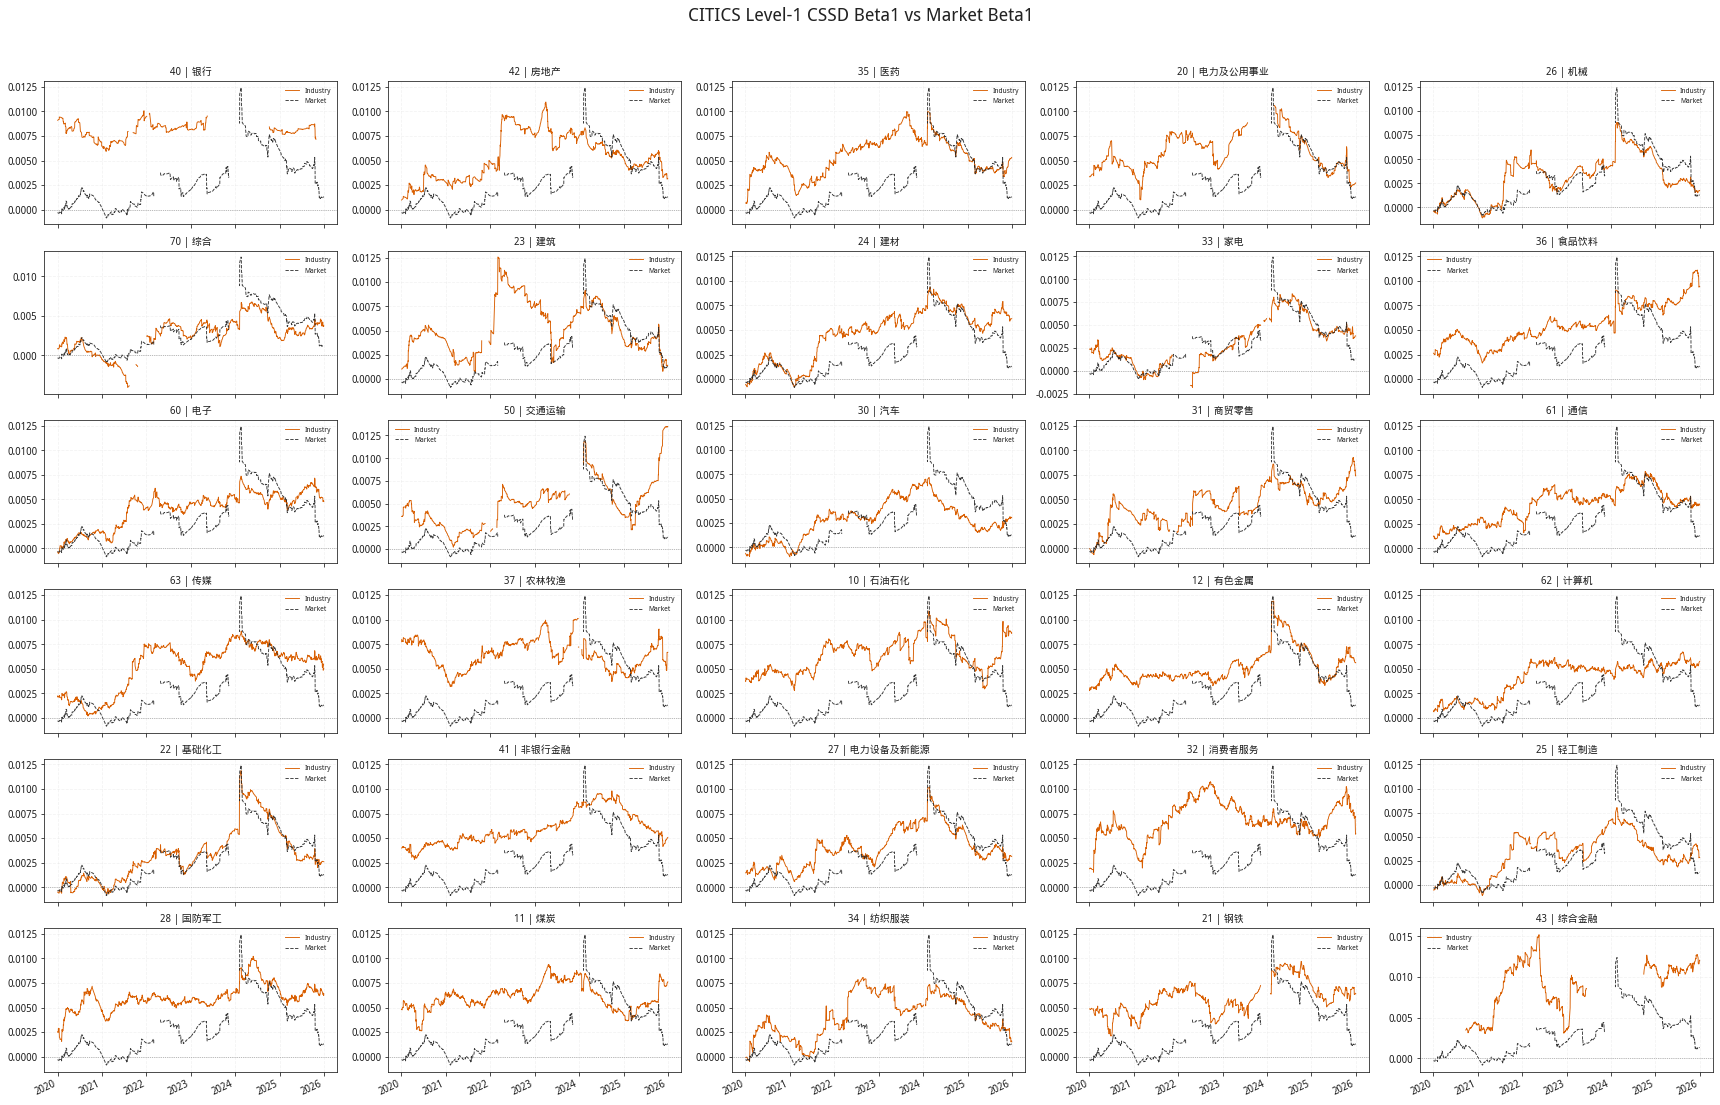

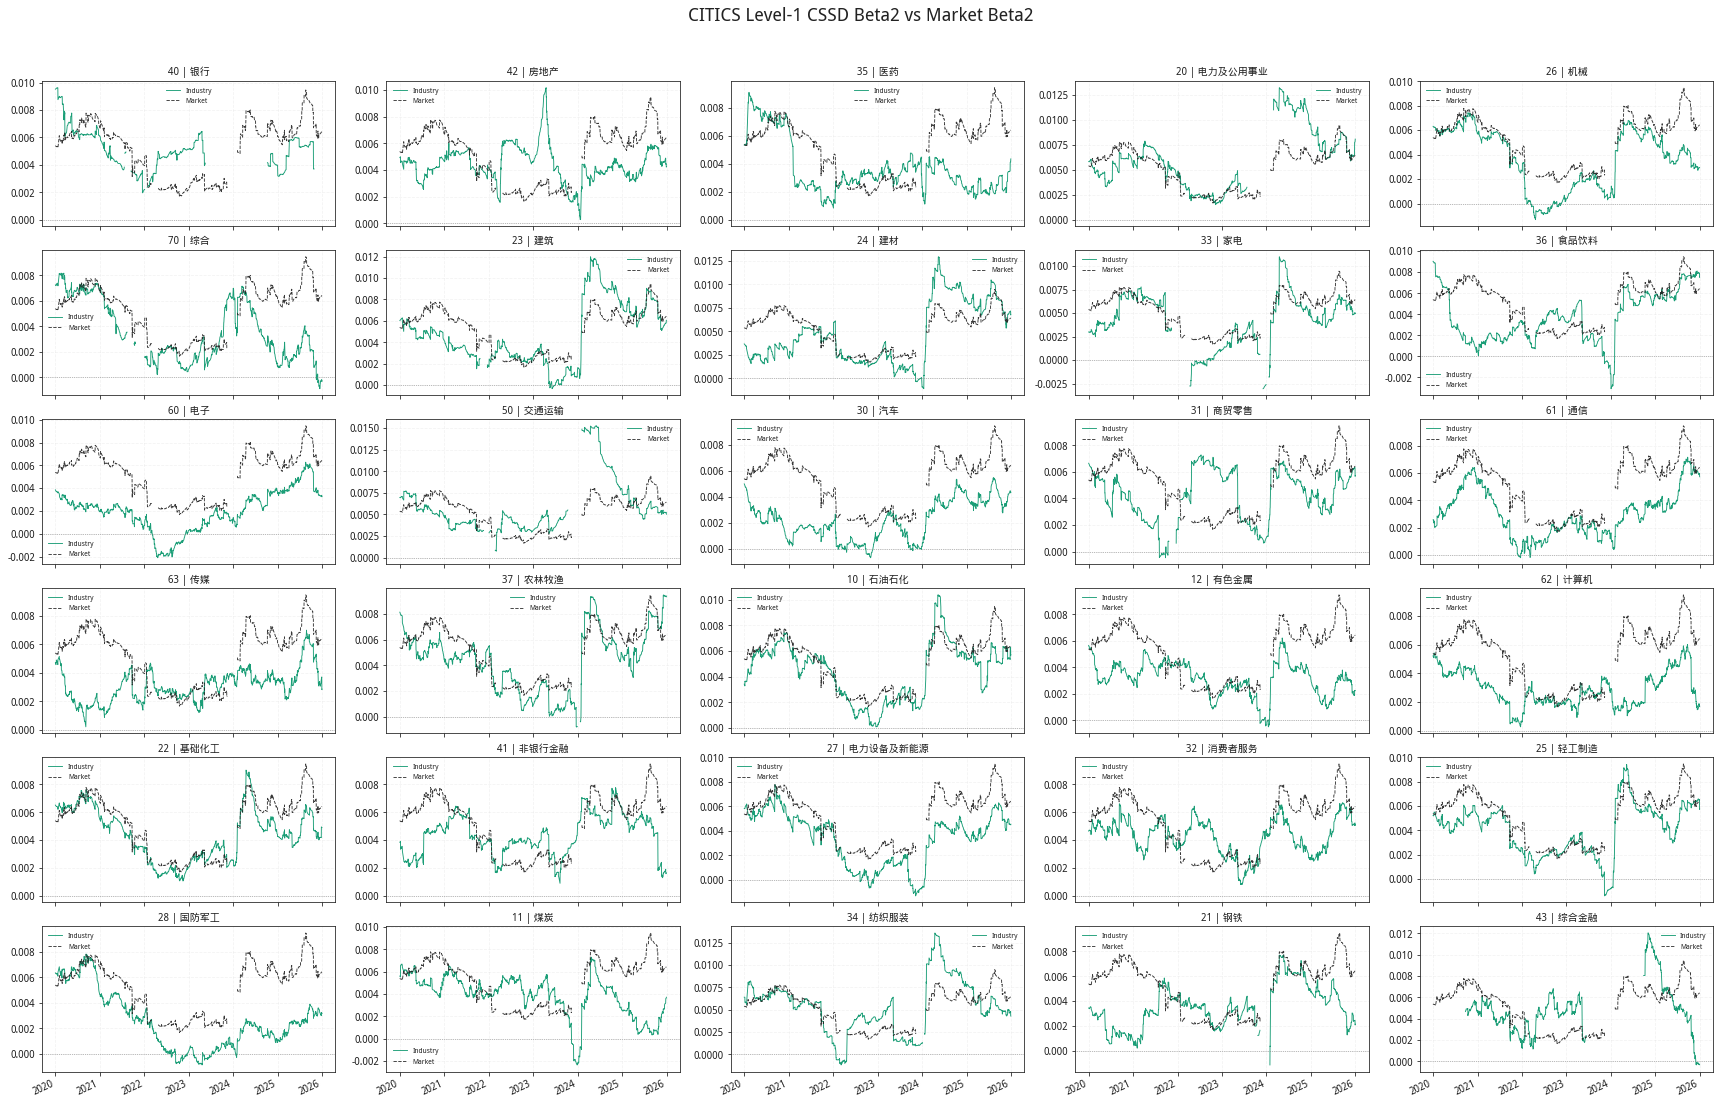

In [13]:
market_beta1 = cssd_beta1.iloc[:, 0].rename("Market")
market_beta2 = cssd_beta2.iloc[:, 0].rename("Market")

fig_beta1 = plot_industry_beta_panels(
    beta_df=beta1,
    market_beta=market_beta1,
    industry_names=cssd_details["industry_names"],
    figure_title="CITICS Level-1 CSSD Beta1 vs Market Beta1",
    ncols=5,
    color="#d95f02",
    use_chinese=True,
)

fig_beta2 = plot_industry_beta_panels(
    beta_df=beta2,
    market_beta=market_beta2,
    industry_names=cssd_details["industry_names"],
    figure_title="CITICS Level-1 CSSD Beta2 vs Market Beta2",
    ncols=5,
    color="#1b9e77",
    use_chinese=True,
)

# fig_all_betas = plot_industry_betas_vs_market(
#     industry_beta1=beta1,
#     industry_beta2=beta2,
#     market_beta1=market_beta1,
#     market_beta2=market_beta2,
#     ncols=5,
# )

从这两张图看，最重要的结论是：你目前捕捉到的主要是“行业分化”，而不是经典意义上的“羊群效应”。

在这个模型中：

$$
\beta_1
=
\overline{\text{CSSD}}_{\text{行业极端上涨日}}
-
\overline{\text{CSSD}}_{\text{普通日}}
$$

$$
\beta_2
=
\overline{\text{CSSD}}_{\text{行业极端下跌日}}
-
\overline{\text{CSSD}}_{\text{普通日}}
$$

因此：

- $\beta>0$：极端行情时 CSSD 上升，行业内个股走势更分化；
- $\beta<0$：极端行情时 CSSD 下降，行业内个股更同步，才是传统 CSSD 模型所说的羊群效应。

你图中的全市场虚线大多为正，且大部分行业实线也为正。这意味着在你设定的“行业或市场单日涨跌超过 2%”条件下，A 股更常见的是：行业整体虽在涨或跌，但内部股票并不整齐划一，而是出现强弱分层、龙头与跟随者分化、子行业轮动。

几个直观现象：

- `Beta1` 普遍更稳定、且多数行业高于全市场。银行、医药、电力公用、食品饮料、石油石化、综合金融等，在行业大涨时通常呈现更明显的内部收益分化。
- `Beta2` 的行业差异明显大于 `Beta1`。下跌行情下，部分行业曾出现接近零甚至负 beta，例如电子、汽车、煤炭等在若干阶段更趋同步；但也有建筑、建材、交通运输、电力公用等行业在 2024 年后出现很高的正 beta，说明下跌时并非齐跌，而是分化更强。
- 行业 `Beta1/Beta2` 与全市场虚线有共同的阶段趋势，但很多行业持续显著高于或低于市场。这种“相对全市场的偏离”比绝对 beta 更值得用于行业配置。
- 曲线的大跳变不应立刻解释为行业结构突变。252 日滚动窗口高度重叠，但极端日数量很少；某一个极端日进入或退出窗口，就可能显著改变均值和 beta。
- 图中的中断仍是此前保留的“极端日不足 5 天则不估计”规则所致，不要把中断误读为 beta 为零或行业没有分化。

建议先生成一张汇总表，避免只靠肉眼比较曲线.

重点看四列：

- `beta1_minus_market_mean`：行业上涨分化是否长期强于全市场；
- `beta2_minus_market_mean`：行业下跌分化是否长期强于全市场；
- `down_minus_up_mean`：下跌时相对上涨时更分化，还是更趋同；
- `beta1_observations`、`beta2_observations`：有效回归日太少的行业，结论可信度应降低。

下一步不应该直接把 beta 用于交易，而应补上每个行业 beta 的 `t` 值、极端日数量和显著性检验。只有“beta 为负且显著”才能较有把握地说该行业存在羊群效应。

In [8]:
def _to_market_series(data, name):
    if isinstance(data, pd.DataFrame):
        if data.shape[1] != 1:
            raise ValueError("{} must have one column.".format(name))
        return data.iloc[:, 0].rename(name)

    return data.rename(name)


def _positive_ratio(series):
    series = series.dropna()

    if len(series) == 0:
        return np.nan

    return (series > 0).mean()


market_b1 = _to_market_series(
    market_beta1,
    "market_beta1",
).reindex(beta1.index)

market_b2 = _to_market_series(
    market_beta2,
    "market_beta2",
).reindex(beta2.index)

beta1_excess = beta1.sub(market_b1, axis=0)
beta2_excess = beta2.sub(market_b2, axis=0) # fix

summary = pd.DataFrame(index=beta1.columns)

summary["industry_name"] = [
    cssd_details["industry_names"].get(code, code)
    for code in summary.index
]

summary["beta1_mean"] = beta1.mean()
summary["beta2_mean"] = beta2.mean()

summary["beta1_positive_ratio"] = beta1.apply(
    _positive_ratio
)
summary["beta2_positive_ratio"] = beta2.apply(
    _positive_ratio
)

summary["beta1_minus_market_mean"] = beta1_excess.mean()
summary["beta2_minus_market_mean"] = beta2_excess.mean()

summary["beta1_minus_market_last252"] = (
    beta1_excess.tail(252).mean()
)

summary["beta2_minus_market_last252"] = (
    beta2_excess.tail(252).mean()
)

summary["down_minus_up_mean"] = (
    beta2 - beta1
).mean()

summary["beta1_observations"] = beta1.count()
summary["beta2_observations"] = beta2.count()

summary = summary.sort_values(
    "beta2_minus_market_last252",
    ascending=False,
)

display(summary)

,industry_name,beta1_mean,beta2_mean,beta1_positive_ratio,beta2_positive_ratio,beta1_minus_market_mean,beta2_minus_market_mean,beta1_minus_market_last252,beta2_minus_market_last252,down_minus_up_mean,beta1_observations,beta2_observations
24,建材,0.004629,0.004598,0.954639,0.972509,0.001645,-0.000372,0.002060,0.001116,-0.000032,1455,1455
20,电力及公用事业,0.005789,0.006058,1.000000,1.000000,0.002943,0.000771,0.000195,0.000587,0.000269,1312,1312
23,建筑,0.005262,0.004742,1.000000,0.983734,0.002089,-0.000328,-0.000640,0.000105,-0.000520,1414,1414
36,食品饮料,0.005624,0.003682,1.000000,0.959450,0.002763,-0.001254,0.004465,-0.000274,-0.001941,1455,1455
37,农林牧渔,0.006475,0.004392,1.000000,0.993741,0.003508,-0.000652,0.001952,-0.000739,-0.002084,1438,1438
50,交通运输,0.005012,0.005996,1.000000,1.000000,0.002071,0.000746,0.002727,-0.000906,0.000984,1325,1325
34,纺织服装,0.004183,0.005285,0.983391,0.960554,0.001269,0.000355,-0.000553,-0.001248,0.001103,1445,1445
10,石油石化,0.006384,0.004426,1.000000,1.000000,0.003359,-0.000643,0.001931,-0.001656,-0.001958,1455,1455
25,轻工制造,0.003162,0.004029,0.919477,0.965588,0.000117,-0.000929,-0.001185,-0.001720,0.000867,1453,1453
43,综合金融,0.008923,0.004842,1.000000,0.975967,0.006277,-0.000109,0.006866,-0.001745,-0.004081,957,957


修正后，之前关于“行业相对全市场下跌分化”的排序需要更新。更准确的结论是：

| 层面 | 修正后的结论 |
|---|---|
| 绝对 CSSD 羊群效应 | 仍不支持多数行业存在持续的经典羊群效应。30 个行业的 `beta1_mean`、`beta2_mean` 都为正，且 beta 为正的滚动窗口占比普遍很高。 |
| 上涨极端行情 | 多数行业的 `beta1` 高于市场，说明行业大涨时通常比全市场更容易出现内部强弱分层。综合金融、银行、消费者服务、石油石化等尤其明显。 |
| 下跌极端行情 | 多数行业的 `beta2` 虽然仍为正，但低于市场，即“下跌时仍分化、但分化程度低于全市场”，不能直接称为羊群效应。 |
| 涨跌不对称 | 多数行业 `down_minus_up_mean < 0`，即下跌时相较上涨时更趋同；这是最稳定、最有经济意义的发现。 |

最核心的一句可以写成：

> 2020—2025 年间，A 股一级行业在极端上涨和下跌日的行业内收益离散度总体均高于普通日，因此不存在广泛而持续的经典 CSSD 羊群效应；但多数行业在下跌极端行情中的离散度增幅显著低于上涨极端行情，表现出明显的“下跌相对趋同、上涨更易分化”的非对称特征。

`beta2_minus_market_mean` 的长期结果显示：

- 下跌时相对全市场更分化的行业主要是：电力及公用事业（`+0.000771`）、交通运输（`+0.000746`）、纺织服装（`+0.000355`）。
- 与市场大致相近的行业包括：综合金融、银行、建筑、建材。
- 下跌时相对全市场更趋同的行业占多数，尤其是电子（`-0.003120`）、汽车（`-0.002926`）、国防军工（`-0.002562`）、计算机（`-0.002305`）、传媒（`-0.002152`）。

最近 252 个交易日的结论更集中：

- 相对市场下跌时更分化：建材（`+0.001116`）、电力及公用事业（`+0.000587`）；建筑基本接近市场（`+0.000105`）。
- 相对市场下跌时更趋同：煤炭（`-0.005285`）、综合（`-0.005238`）、医药（`-0.004568`）、有色金属（`-0.004554`）、国防军工（`-0.004450`）最突出。

但要严格区分：

- `beta2_minus_market < 0`：相对全市场更同步；
- `beta2 < 0` 且统计显著：绝对意义上的 CSSD 羊群效应。

例如煤炭近期相对市场更趋同，并不表示煤炭行业的个股在极端下跌时已经“齐跌”；它的长期 `beta2_mean=0.003821` 仍为正，意味着相对普通日而言，极端下跌日的行业内分化总体仍然更高，只是低于全市场同期程度。

从行业配置角度，建议把因子改名为更准确的：

```python
relative_downside_dispersion = beta2 - market_beta2
```

- 值高：该行业在极端下跌时比市场更分化；
- 值低：该行业在极端下跌时比市场更趋同。

这可以作为行业轮动的候选排序信号，但不能预设“高值必然有更高未来收益”或“低值必然更防御”。应分别回测高分组、低分组相对行业平均指数的未来收益，再决定实际交易方向。

最后两个口径问题仍值得处理：

- 你的市场 CSSD 原函数覆盖全部 `CS` 股票，而行业代码排除了 B 股；若继续比较行业 beta 与市场 beta，应统一股票池。
- 行业间 raw beta 会受基础波动率和成分股数影响。后续建议增加 `beta2 / normal_cssd`、滚动 t 值和极端日数量，再做横截面排序。

In [14]:
import numpy as np
import pandas as pd


def make_cssd_selection_score(
    beta1,
    beta2,
    mode="down",
    thesis="dispersion",
):
    """
    输出：日期 × 行业的 0~1 选股分数，数值越高越应被优先买入。

    mode:
        "up"    : 使用 beta1
        "down"  : 使用 beta2
        "blend" : beta1、beta2 的横截面分位数平均

    thesis:
        "dispersion"      : 买高 beta，即极端行情中更分化的行业
        "synchronization" : 买低 beta，即极端行情中相对更趋同的行业
    """
    beta1, beta2 = beta1.align(beta2, join="inner")

    rank1 = beta1.rank(axis=1, pct=True)
    rank2 = beta2.rank(axis=1, pct=True)

    if mode == "up":
        score = rank1
    elif mode == "down":
        score = rank2
    elif mode == "blend":
        score = 0.5 * rank1 + 0.5 * rank2
    else:
        raise ValueError("mode 必须是 'up'、'down' 或 'blend'。")

    if thesis == "dispersion":
        return score
    elif thesis == "synchronization":
        return 1.0 - score
    else:
        raise ValueError(
            "thesis 必须是 'dispersion' 或 'synchronization'。"
        )


def download_industry_index_close(
    industry_index_map,
    start_date,
    end_date,
):
    """
    下载行业指数收盘价。

    industry_index_map 的 key 必须是 beta1/beta2 的行业代码，
    value 是米筐中对应行业指数的 order_book_id。

    注意：必须使用与 CSSD 行业分类一致的指数体系。
    你的因子使用 citics_2019 一级行业，因此这里也应使用中信一级行业指数。
    """
    from rqdatac import get_price

    index_ids = list(industry_index_map.values())

    raw = get_price(
        order_book_ids=index_ids,
        start_date=start_date,
        end_date=end_date,
        frequency="1d",
        fields=["close"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        raise RuntimeError("未下载到行业指数价格。")

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
    else:
        close = raw["close"].to_frame(name=index_ids[0])

    close.index = pd.to_datetime(close.index)

    id_to_industry = {
        str(index_id): industry_code
        for industry_code, index_id in industry_index_map.items()
    }

    close.columns = [
        id_to_industry.get(str(column), column)
        for column in close.columns
    ]

    return close.sort_index()


def _rebalance_dates(trading_dates, rebalance):
    if rebalance == "D":
        return pd.DatetimeIndex(trading_dates)

    date_series = pd.Series(
        trading_dates,
        index=trading_dates,
    )

    return pd.DatetimeIndex(
        date_series.groupby(
            trading_dates.to_period(rebalance)
        ).max().values
    )


def _performance_summary(result, annual_days=252):
    valid = result[
        ["strategy_net", "industry_average", "active_return"]
    ].dropna()

    if valid.empty:
        raise ValueError("没有可用于评价的回测收益。")

    strategy_return = valid["strategy_net"]
    benchmark_return = valid["industry_average"]
    active_return = valid["active_return"]

    strategy_nav = (1.0 + strategy_return).cumprod()
    benchmark_nav = (1.0 + benchmark_return).cumprod()

    strategy_cagr = (
        strategy_nav.iloc[-1] ** (annual_days / len(strategy_return))
        - 1.0
    )

    benchmark_cagr = (
        benchmark_nav.iloc[-1] ** (annual_days / len(benchmark_return))
        - 1.0
    )

    tracking_error = (
        active_return.std(ddof=1) * np.sqrt(annual_days)
    )

    information_ratio = (
        active_return.mean() * annual_days / tracking_error
        if tracking_error > 0 else np.nan
    )

    max_drawdown = (
        strategy_nav / strategy_nav.cummax() - 1.0
    ).min()

    return pd.Series({
        "strategy_cagr": strategy_cagr,
        "benchmark_cagr": benchmark_cagr,
        "annualized_active_return": (
            active_return.mean() * annual_days
        ),
        "tracking_error": tracking_error,
        "information_ratio": information_ratio,
        "active_win_rate": (active_return > 0).mean(),
        "max_drawdown": max_drawdown,
    })


def backtest_industry_cssd(
    score,
    industry_index_close,
    top_n=5,
    rebalance="M",
    signal_lag=2,
    transaction_cost_bps=10,
):
    """
    行业指数多头回测。

    - 月末生成行业排序；
    - 买入得分最高的 top_n 个行业；
    - 等权持有；
    - 基准：全部可用行业指数的日等权平均收益；
    - signal_lag=2 是较保守的收盘数据实现：
      T 日得到因子，至少延迟一个完整交易日后才记收益。
    """
    common_columns = score.columns.intersection(
        industry_index_close.columns
    )

    if len(common_columns) < top_n:
        raise ValueError("可匹配的行业指数数量少于 top_n。")

    close = (
        industry_index_close[common_columns]
        .sort_index()
        .astype(float)
    )

    index_return = close.pct_change(fill_method=None)

    score = score.reindex(
        index=index_return.index,
        columns=common_columns,
    )

    # 当日没有指数价格，不允许当日被选入。
    score = score.where(close.notna())

    rebalance_dates = _rebalance_dates(
        index_return.index,
        rebalance=rebalance,
    )

    target_weight = pd.DataFrame(
        np.nan,
        index=index_return.index,
        columns=common_columns,
    )

    selected_industries = {}

    for date in rebalance_dates:
        available_score = score.loc[date].dropna()

        if len(available_score) < top_n:
            continue

        picked = available_score.nlargest(top_n).index

        target_weight.loc[date] = 0.0
        target_weight.loc[date, picked] = 1.0 / len(picked)

        selected_industries[date] = list(picked)

    # 月末信号，下一期才生效；避免把当日收盘信息用于当日收益。
    weight = (
        target_weight.ffill()
        .shift(signal_lag)
        .fillna(0.0)
    )

    has_position = weight.sum(axis=1).gt(0)

    missing_return_while_holding = (
        weight.ne(0.0) & index_return.isna()
    )

    if missing_return_while_holding.any().any():
        problem = missing_return_while_holding.stack()
        problem = problem[problem].index.tolist()[:5]

        raise ValueError(
            "持仓期间存在缺失的行业指数收益，示例：{}".format(problem)
        )

    gross_return = (
        weight * index_return.fillna(0.0)
    ).sum(axis=1)

    turnover = weight.diff().abs().sum(axis=1)
    turnover.iloc[0] = weight.iloc[0].abs().sum()

    transaction_cost = turnover * transaction_cost_bps / 10000.0

    strategy_net = (
        gross_return - transaction_cost
    ).where(has_position)

    # 行业平均指数：当日所有可用行业指数的等权平均收益。
    industry_average = index_return.mean(axis=1).where(has_position)

    result = pd.DataFrame({
        "strategy_gross": gross_return.where(has_position),
        "turnover": turnover.where(has_position),
        "transaction_cost": transaction_cost.where(has_position),
        "strategy_net": strategy_net,
        "industry_average": industry_average,
    })

    result["active_return"] = (
        result["strategy_net"] - result["industry_average"]
    )

    result["strategy_nav"] = (
        1.0 + result["strategy_net"].fillna(0.0)
    ).cumprod()

    result["benchmark_nav"] = (
        1.0 + result["industry_average"].fillna(0.0)
    ).cumprod()

    summary = _performance_summary(result)

    selected_industries = pd.Series(
        selected_industries,
        name="selected_industries",
    )

    return result, weight, selected_industries, summary

In [15]:
industry_index_map = {
    # 中信 2019 一级行业代码: RQData 行业指数 order_book_id
    "10": "CI005001.INDX",  # 石油石化
    "11": "CI005002.INDX",  # 煤炭
    "12": "CI005003.INDX",  # 有色金属

    "20": "CI005004.INDX",  # 电力及公用事业
    "21": "CI005005.INDX",  # 钢铁
    "22": "CI005006.INDX",  # 基础化工
    "23": "CI005007.INDX",  # 建筑
    "24": "CI005008.INDX",  # 建材
    "25": "CI005009.INDX",  # 轻工制造
    "26": "CI005010.INDX",  # 机械
    "27": "CI005011.INDX",  # 电力设备及新能源
    "28": "CI005012.INDX",  # 国防军工

    "30": "CI005013.INDX",  # 汽车
    "31": "CI005014.INDX",  # 商贸零售
    "32": "CI005015.INDX",  # 消费者服务
    "33": "CI005016.INDX",  # 家电
    "34": "CI005017.INDX",  # 纺织服装
    "35": "CI005018.INDX",  # 医药
    "36": "CI005019.INDX",  # 食品饮料
    "37": "CI005020.INDX",  # 农林牧渔

    "40": "CI005021.INDX",  # 银行
    "41": "CI005022.INDX",  # 非银行金融
    "42": "CI005023.INDX",  # 房地产
    "43": "CI005030.INDX",  # 综合金融

    "50": "CI005024.INDX",  # 交通运输

    "60": "CI005025.INDX",  # 电子
    "61": "CI005026.INDX",  # 通信
    "62": "CI005027.INDX",  # 计算机
    "63": "CI005028.INDX",  # 传媒

    "70": "CI005029.INDX",  # 综合
}

index_catalog = all_instruments("INDX").copy()

available_ids = set(
    index_catalog["order_book_id"].astype(str)
)

missing_ids = sorted(
    set(industry_index_map.values()) - available_ids
)

if missing_ids:
    raise ValueError(
        "以下行业指数不在当前 RQData 权限或指数库中：{}".format(
            missing_ids
        )
    )

catalog_columns = [
    column
    for column in [
        "order_book_id",
        "symbol",
        "listed_date",
        "de_listed_date",
    ]
    if column in index_catalog.columns
]

display(
    index_catalog[
        index_catalog["order_book_id"].isin(
            industry_index_map.values()
        )
    ][catalog_columns].sort_values("order_book_id")
)

,order_book_id,symbol,listed_date,de_listed_date
5068,CI005001.INDX,中信石油石化,2010-04-19,0000-00-00
5069,CI005002.INDX,中信煤炭,2010-06-29,0000-00-00
5070,CI005003.INDX,中信有色金属,2010-06-29,0000-00-00
5071,CI005004.INDX,中信电力及公用事业,2010-06-29,0000-00-00
5072,CI005005.INDX,中信钢铁,2010-06-29,0000-00-00
5073,CI005006.INDX,中信基础化工,2010-04-20,0000-00-00
5074,CI005007.INDX,中信建筑,2010-06-29,0000-00-00
5075,CI005008.INDX,中信建材,2010-06-29,0000-00-00
5076,CI005009.INDX,中信轻工制造,2010-06-29,0000-00-00
5077,CI005010.INDX,中信机械,2010-06-29,0000-00-00


CI005030.INDX（综合金融）自 2019-11-29 起有数据；回测从 2020 年开始，因此可保留该行业，但应继续关注其较低的有效 beta 观测数。

In [18]:
industry_index_close = download_industry_index_close(
    industry_index_map=industry_index_map,
    start_date=beta1.index.min() - pd.Timedelta(days=10),
    end_date=beta1.index.max(),
)

industry_index_close = industry_index_close.reindex(
    columns=beta1.columns
)

display(industry_index_close.tail())
display(industry_index_close.isna().mean().sort_values(ascending=False))

,40,42,35,20,26,70,23,24,33,36,...,22,41,27,32,25,28,11,34,21,43
date,,,,,,,,,,,,,,,,,,,,,
2025-12-25,11966.3526,4151.5492,11031.5612,3124.2808,8625.7791,3268.4278,3812.0829,7221.2826,19670.9412,23366.4139,...,7169.4997,11127.5013,12138.0107,7377.0837,3860.4354,11314.1296,3615.8248,3324.5790,1935.0446,936.9910
2025-12-26,11925.7149,4158.7563,10994.0098,3132.7164,8641.5902,3263.7213,3814.4845,7244.7590,19646.4705,23267.8777,...,7251.9776,11178.5209,12273.1189,7555.4468,3843.5499,11446.6294,3622.4128,3322.6840,1961.4444,940.0231
2025-12-29,12049.9331,4138.5364,10878.6057,3095.9258,8672.1037,3269.9485,3823.0328,7194.5890,19601.9712,23019.5862,...,7184.8098,11087.8743,12156.4875,7532.9693,3839.9869,11646.1785,3632.2368,3316.0851,1959.8399,980.1104
2025-12-30,12031.1593,4094.1796,10820.2311,3065.5857,8736.3813,3251.1038,3811.4031,7139.4137,19783.2306,22876.1512,...,7211.2715,11016.3908,12148.8775,7453.0671,3821.2516,11594.9120,3616.1787,3328.1523,1949.1294,972.0539
2025-12-31,12043.3108,4130.3025,10771.7565,3059.1081,8727.5838,3240.1346,3820.5924,7154.4493,19781.9843,22737.6132,...,7188.0440,10962.8401,12044.5915,7643.1129,3820.9497,11884.7152,3595.7003,3341.0822,1950.5757,988.2143


40    0.0
42    0.0
21    0.0
34    0.0
11    0.0
28    0.0
25    0.0
32    0.0
27    0.0
41    0.0
22    0.0
62    0.0
12    0.0
10    0.0
37    0.0
63    0.0
61    0.0
31    0.0
30    0.0
50    0.0
60    0.0
36    0.0
33    0.0
24    0.0
23    0.0
70    0.0
26    0.0
20    0.0
35    0.0
43    0.0
dtype: float64

In [19]:
# 策略 A：选择在极端下跌时更分化的行业
down_dispersion_score = make_cssd_selection_score(
    beta1=beta1,
    beta2=beta2,
    mode="down",
    thesis="dispersion",
)

result_a, weight_a, holdings_a, summary_a = backtest_industry_cssd(
    score=down_dispersion_score,
    industry_index_close=industry_index_close,
    top_n=5,
    rebalance="M",
    signal_lag=2,
    transaction_cost_bps=10,
)

display(summary_a)
display(holdings_a.tail())

strategy_cagr               0.077324
benchmark_cagr              0.094353
annualized_active_return   -0.014659
tracking_error              0.086553
information_ratio          -0.169363
active_win_rate             0.491655
max_drawdown               -0.303793
dtype: float64

2025-08-29    [24, 23, 20, 37, 36]
2025-09-30    [20, 24, 23, 37, 36]
2025-10-31    [36, 24, 37, 20, 10]
2025-11-28    [37, 36, 20, 25, 32]
2025-12-31    [37, 20, 36, 24, 23]
Name: selected_industries, dtype: object

In [20]:
# 策略 B：选择在极端下跌时相对更趋同的行业
down_sync_score = make_cssd_selection_score(
    beta1=beta1,
    beta2=beta2,
    mode="down",
    thesis="synchronization",
)

result_b, weight_b, holdings_b, summary_b = backtest_industry_cssd(
    score=down_sync_score,
    industry_index_close=industry_index_close,
    top_n=5,
    rebalance="M",
    signal_lag=2,
    transaction_cost_bps=10,
)

display(summary_b)

strategy_cagr               0.099930
benchmark_cagr              0.094353
annualized_active_return    0.011869
tracking_error              0.094619
information_ratio           0.125440
active_win_rate             0.495132
max_drawdown               -0.394443
dtype: float64

,下跌分化行业组合,下跌趋同行业组合
strategy_cagr,0.077324,0.099930
benchmark_cagr,0.094353,0.094353
annualized_active_return,-0.014659,0.011869
tracking_error,0.086553,0.094619
information_ratio,-0.169363,0.125440
active_win_rate,0.491655,0.495132
max_drawdown,-0.303793,-0.394443


<AxesSubplot:title={'center':'CSSD 行业选择策略 vs 行业平均指数'}, xlabel='date'>

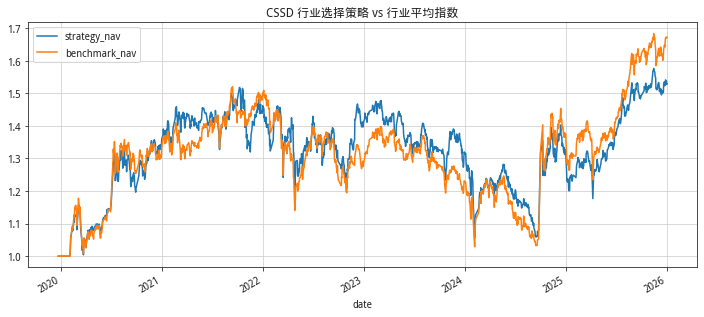

In [21]:
comparison = pd.DataFrame({
    "下跌分化行业组合": summary_a,
    "下跌趋同行业组合": summary_b,
})

display(comparison)

result_a[["strategy_nav", "benchmark_nav"]].plot(
    figsize=(12, 5),
    title="CSSD 行业选择策略 vs 行业平均指数",
    grid=True,
)